In [1]:
import sys
sys.path.append('..')
import matplotlib.pyplot as plt
import shap
from src import models

/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


## load data + features

same pipeline as the eda notebook (filter residential, trim outliers) plus the hex/distance/trailing features from `features.py`.

In [2]:
df = models.load_dataset()
df.shape

(240927, 25)

## model comparison

linear regression, gam (factor terms on property attrs, smooth terms on distance + hex features), and xgboost. all scored on log10(price) with 5-fold spatial block cv (grouped by coarse hex, not random k-fold -- see `spatial_diagnostics.py`).

In [3]:
results = models.compare_models(df)
results

/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/cam/

/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/cam/

/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/scipy/linalg/_basic.py:1449: RuntimeWarning: divide by zero encountered in matmul
  B = (u @ vh[:rank]).conj().T
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/scipy/linalg/_basic.py:1449: RuntimeWarning: overflow encountered in matmul
  B = (u @ vh[:rank]).conj().T
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/scipy/linalg/_basic.py:1449: RuntimeWarning: invalid value encountered in matmul
  B = (u @ vh[:rank]).conj().T


/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/scipy/linalg/_basic.py:1449: RuntimeWarning: divide by zero encountered in matmul
  B = (u @ vh[:rank]).conj().T
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/scipy/linalg/_basic.py:1449: RuntimeWarning: overflow encountered in matmul
  B = (u @ vh[:rank]).conj().T
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/scipy/linalg/_basic.py:1449: RuntimeWarning: invalid value encountered in matmul
  B = (u @ vh[:rank]).conj().T


/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/scipy/linalg/_basic.py:1449: RuntimeWarning: divide by zero encountered in matmul
  B = (u @ vh[:rank]).conj().T
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/scipy/linalg/_basic.py:1449: RuntimeWarning: overflow encountered in matmul
  B = (u @ vh[:rank]).conj().T
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/scipy/linalg/_basic.py:1449: RuntimeWarning: invalid value encountered in matmul
  B = (u @ vh[:rank]).conj().T


/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/scipy/linalg/_basic.py:1449: RuntimeWarning: divide by zero encountered in matmul
  B = (u @ vh[:rank]).conj().T
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/scipy/linalg/_basic.py:1449: RuntimeWarning: overflow encountered in matmul
  B = (u @ vh[:rank]).conj().T
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/scipy/linalg/_basic.py:1449: RuntimeWarning: invalid value encountered in matmul
  B = (u @ vh[:rank]).conj().T


/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/scipy/linalg/_basic.py:1449: RuntimeWarning: divide by zero encountered in matmul
  B = (u @ vh[:rank]).conj().T
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/scipy/linalg/_basic.py:1449: RuntimeWarning: overflow encountered in matmul
  B = (u @ vh[:rank]).conj().T
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/scipy/linalg/_basic.py:1449: RuntimeWarning: invalid value encountered in matmul
  B = (u @ vh[:rank]).conj().T


,rmse,mae,r2
linear,0.167288,0.122075,0.569987
gam,0.163333,0.118976,0.588830
xgboost,0.159901,0.115568,0.606023


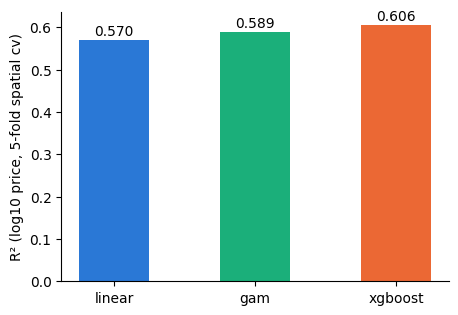

In [4]:
colors = {"linear": "#2a78d6", "gam": "#1baf7a", "xgboost": "#eb6834"}
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(results.index, results["r2"], color=[colors[m] for m in results.index], width=0.5)
ax.set_ylabel("R² (log10 price, 5-fold spatial cv)")
ax.spines[["top", "right"]].set_visible(False)
for i, v in enumerate(results["r2"]):
    ax.text(i, v + 0.01, f"{v:.3f}", ha="center")
plt.show()

xgboost edges out the gam and linear baseline, but the gap is modest -- most of the signal is in the hex-level features shared across all three, not the model class.

## moran's i on residuals: baseline vs hex features

residuals are out-of-fold predictions from the spatial cv, not in-sample -- an in-sample fit understates residual autocorrelation because the model has already absorbed local structure. `baseline` uses property attributes + distance-to-centre only; `hex features` adds hex trailing price/count and the neighbour lag.

In [5]:
moran_df = models.moran_before_after(df)
moran_df

/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/cam/

/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/cam/

/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/cam/

/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/cam/

('WARNING: ', '88195d344bfffff', ' is an island (no neighbors)')
('WARNING: ', '88195d344bfffff', ' is an island (no neighbors)')


/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/libpysal/weights/weights.py:224: UserWarning: The weights matrix is not fully connected: 
 There are 3 disconnected components.
 There is 1 island with id: 88195d344bfffff.
  warnings.warn(message)


,moran_i,p_sim
baseline (no hex features),0.727066,0.001
hex features,0.485148,0.001


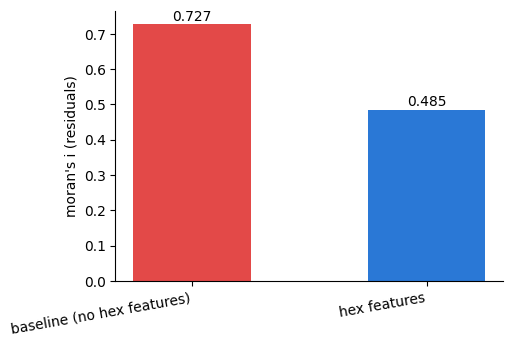

In [6]:
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(moran_df.index, moran_df["moran_i"], color=["#e34948", "#2a78d6"], width=0.5)
ax.set_ylabel("moran's i (residuals)")
ax.spines[["top", "right"]].set_visible(False)
plt.xticks(rotation=10, ha="right")
for i, v in enumerate(moran_df["moran_i"]):
    ax.text(i, v + 0.01, f"{v:.3f}", ha="center")
plt.show()

hex features cut moran's i roughly in half (0.73 → 0.49), both still significant at p=0.001. the hex-price proxy is absorbing real spatial structure, but residual clustering doesn't disappear -- there's still location signal the model isn't capturing (condition, exact street, view, school catchment). worth stating plainly in the readme rather than implying the spatial problem is solved.

## shap: what's driving xgboost's predictions

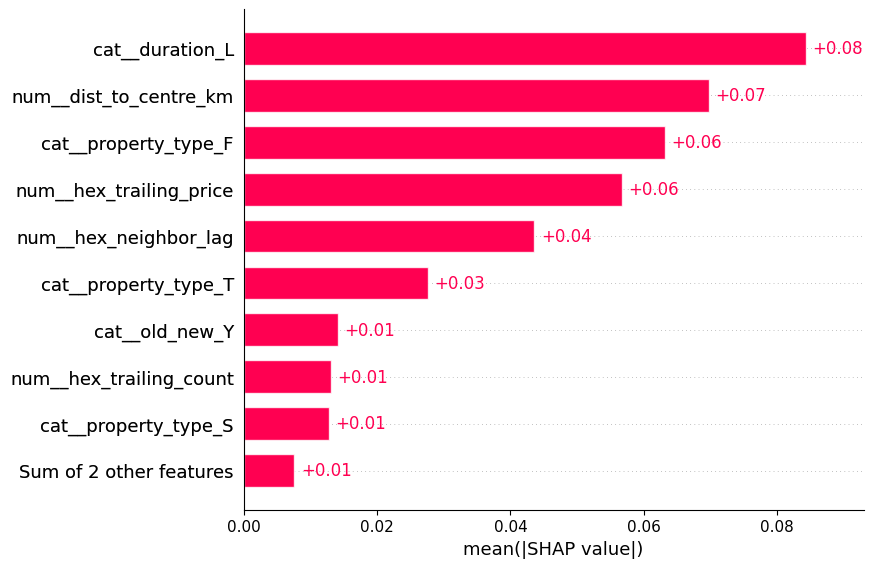

In [7]:
exp = models.shap_summary(df)
shap.plots.bar(exp)

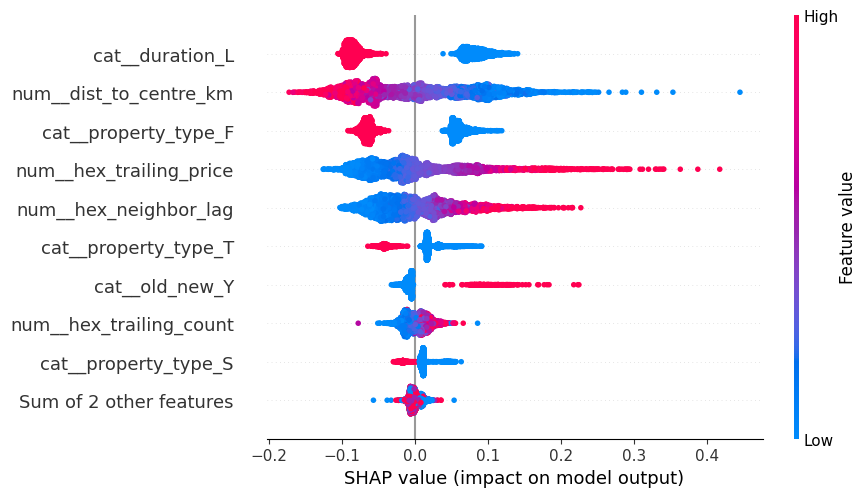

In [8]:
shap.plots.beeswarm(exp)

tenure (leasehold vs freehold), distance-to-centre, and property type dominate, with the hex trailing price and neighbour lag close behind -- consistent with the moran's i result: the hex features are carrying real, currently-unexplained spatial signal, not noise.